<a href="https://colab.research.google.com/github/cv2507/MASY1500_GROUP8_SNOWFLAKE_M2/blob/main/CFPB_Final_Visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CFPB Consumer Complaints - Final Notebook (Milestone 4)
**MASY1-GC1500 Group 8** · Data: `CFPB_CAPSTONE_DB.CFPB_SCHEMA` (Snowflake), pulled live with `pandas.read_sql`.

**Problem statement:** Which financial institutions, products and regions generated the most CFPB complaints between August 2023 and August 2026, and how well did companies respond to them?

Query numbers refer to the team's final SQL script.

In [1]:
%pip install -q "snowflake-connector-python[pandas]" snowflake-sqlalchemy "sqlalchemy<2.1" seaborn

## Connection to Snowflake
# Remember to change the username to whatever it is for snowflake and the associated password

In [2]:
import os
import getpass
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from snowflake.sqlalchemy import URL
from sqlalchemy import create_engine

if "SNOWFLAKE_PASSWORD" not in os.environ:
    os.environ["SNOWFLAKE_PASSWORD"] = getpass.getpass("Snowflake password: ")

engine = create_engine(URL(
    account=os.environ.get("SNOWFLAKE_ACCOUNT", "gsvfbpn-hl39049"),
    user=os.environ.get("SNOWFLAKE_USER", "cv2507"), # username
    password=os.environ["SNOWFLAKE_PASSWORD"],
    database="CFPB_CAPSTONE_DB",
    schema="CFPB_SCHEMA",
    warehouse=os.environ.get("SNOWFLAKE_WAREHOUSE", "COMPUTE_WH"),
    role=os.environ.get("SNOWFLAKE_ROLE", "PUBLIC"),
))

pd.read_sql("select count(*) as complaint_rows from consumer_complaints", engine)

Snowflake password: ··········


,complaint_rows
0,10000


In [ ]:
# code for the chart design
sns.set_theme(style="whitegrid", context="notebook")
BAR = "#2a78d6"
INK = "#52514e"
plt.rcParams.update({"axes.edgecolor": "#c3c2b7", "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK})


def label_bars(ax, fmt="{:,.0f}"):
    """Write each bar's value at its end, in text ink (not the bar color)."""
    for bar in ax.patches:
        if bar.get_width() == 0:
            continue
        ax.annotate(fmt.format(bar.get_width()),
                    (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                    xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=9, color=INK)

### Q1. Which 10 companies receive the most consumer complaints?
*Why it matters:* a compliance analyst needs to know which institutions carry the most complaint volume before comparing how well they handle it. (Same query as SQL Q1.)

In [ ]:
q1 = """
select fc.company_name, count(*) as complaint_count
from consumer_complaints cc
join financial_companies fc on fc.company_id = cc.company_id
group by fc.company_name
order by complaint_count desc
fetch first 10 rows only
"""
top_companies = pd.read_sql(q1, engine)
top_companies["complaint_count"] = top_companies["complaint_count"].astype(int)
top_companies

,company_name,complaint_count
0,Experian Information Solutions Inc.,5892
1,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",2556
2,"EQUIFAX, INC.",553
3,SYNCHRONY FINANCIAL,83
4,"BANK OF AMERICA, NATIONAL ASSOCIATION",66
5,Conduent Incorporated,56
6,"Kriya Capital, LLC",42
7,"National Credit Adjusters, LLC",40
8,CAPITAL ONE FINANCIAL CORPORATION,31
9,WELLS FARGO & COMPANY,29


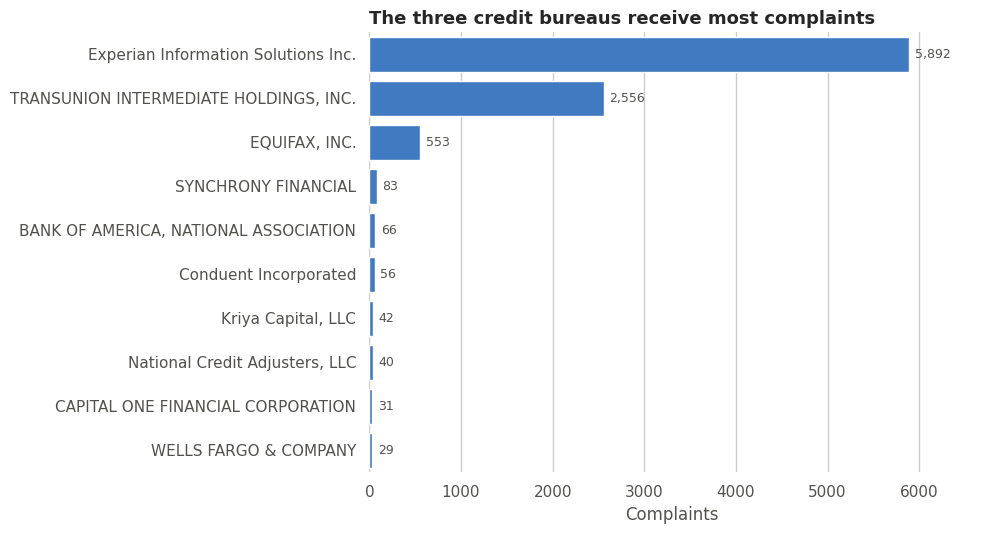

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=top_companies, y="company_name", x="complaint_count", color=BAR, ax=ax)
label_bars(ax)
ax.set_title("The three credit bureaus receive most complaints", loc="left")
ax.set(xlabel="Complaints", ylabel="")
ax.margins(x=0.12)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

**Finding:** Experian, TransUnion and Equifax together account for most complaints in the sample, far ahead of any bank or lender.

## Q2. Which 10 states generate the most complaints?
*Why it matters:* regional concentration shows where consumer pain points cluster and where outreach or supervision would reach the most people. (Same query as SQL Q4.)

In [ ]:
q4 = """
select gl.state_code, count(*) as complaint_count,
       round(ratio_to_report(count(*)) over () * 100, 2) as pct_of_complaints
from consumer_complaints cc
join geographic_locations gl on gl.location_id = cc.location_id
where gl.state_code != 'UNKNOWN'
group by gl.state_code
order by complaint_count desc
fetch first 10 rows only
"""
top_states = pd.read_sql(q4, engine)
top_states["complaint_count"] = top_states["complaint_count"].astype(int)
top_states["pct_of_complaints"] = top_states["pct_of_complaints"].astype(float)
top_states

,state_code,complaint_count,pct_of_complaints
0,TX,1601,16.04
1,FL,1500,15.03
2,CA,896,8.98
3,GA,734,7.35
4,NY,521,5.22
5,NC,356,3.57
6,IL,342,3.43
7,PA,326,3.27
8,AL,312,3.13
9,NJ,266,2.67


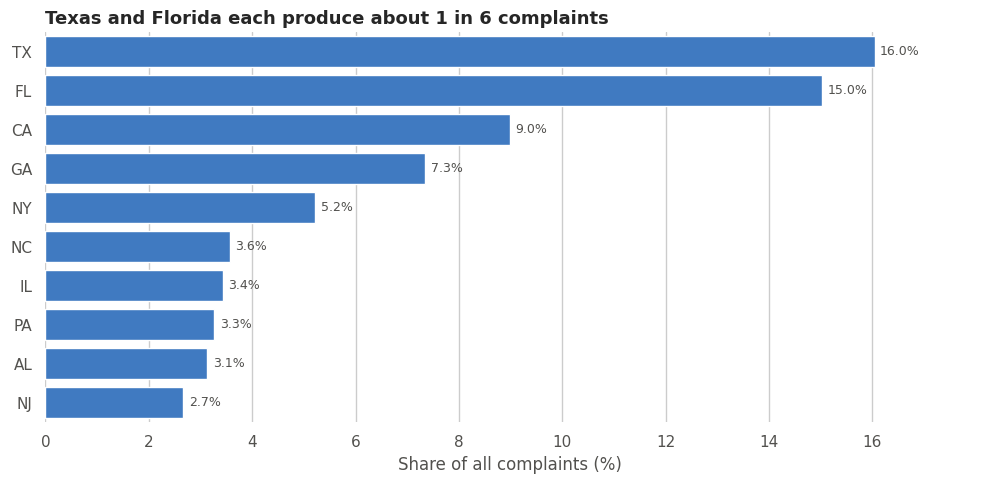

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=top_states, y="state_code", x="pct_of_complaints", color=BAR, ax=ax)
label_bars(ax, fmt="{:.1f}%")
ax.set_title("Texas and Florida each produce about 1 in 6 complaints", loc="left")
ax.set(xlabel="Share of all complaints (%)", ylabel="")
ax.margins(x=0.12)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

**Finding:** TX and FL lead by a wide margin. Together they produce more complaints than the next four states combined.

## Q3. How has daily complaint volume changed over the most recent period?
*Why it matters:* tracking volume over time shows whether complaints are rising or falling and flags spikes worth investigating.

*Data note:* about 98% of the sample was received in July-August 2026, so this chart covers that window by day. A monthly view (SQL Q15) is mostly one spike. A longer time series needs a sample that spans more months.

In [ ]:
q_daily = """
select cc.date_received, count(*) as complaint_count
from consumer_complaints cc
where cc.date_received >= date '2026-07-01'
group by cc.date_received
order by cc.date_received
"""
daily = pd.read_sql(q_daily, engine)
daily["date_received"] = pd.to_datetime(daily["date_received"])
daily["complaint_count"] = daily["complaint_count"].astype(int)
daily.tail()

,date_received,complaint_count
50,2026-08-20,41
51,2026-08-21,10
52,2026-08-22,3
53,2026-08-23,5
54,2026-08-24,4


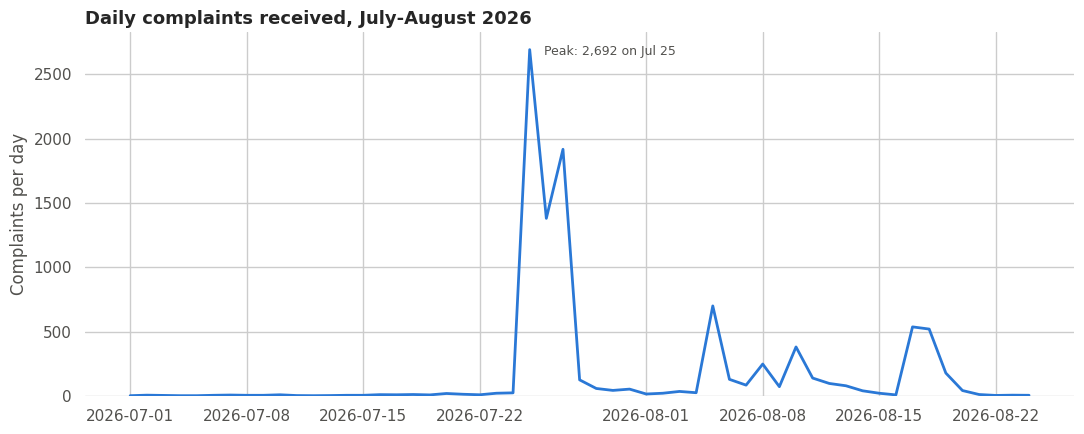

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.lineplot(data=daily, x="date_received", y="complaint_count", color=BAR, linewidth=2, ax=ax)
peak = daily.loc[daily["complaint_count"].idxmax()]
ax.annotate(f"Peak: {peak['complaint_count']:,} on {peak['date_received']:%b %d}",
            (peak["date_received"], peak["complaint_count"]),
            xytext=(10, -4), textcoords="offset points", fontsize=9, color=INK)
ax.set_title("Daily complaints received, July-August 2026", loc="left")
ax.set(xlabel="", ylabel="Complaints per day")
ax.set_ylim(bottom=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

**Finding:** Daily complaint volume stays near zero through mid-July before spiking sharply to a peak of **2,692 complaints on July 25, 2026**, followed by smaller spikes on August 5 (699) and August 17 (536). Together, the top five filing days account for **72.24%** of the sample (7,224 complaints), confirming heavy batch clustering rather than a smooth time series.

## Q4. Which companies respond late most often?
*Why it matters:* the timely-response rate is the CFPB's own measure of whether a company handles complaints on time, so late responders are the institutions falling behind their peers. Companies with at least 20 complaints, to avoid ranking on one or two cases. (Same query as SQL Q5.)

In [ ]:
q5 = """
select company_name, company_total, late_count,
       round(late_share * 100, 2) as pct_not_timely
from (
    select fc.company_name, cc.timely_response,
           count(*) as late_count,
           sum(count(*)) over (partition by fc.company_name) as company_total,
           ratio_to_report(count(*)) over (partition by fc.company_name) as late_share
    from consumer_complaints cc
    join financial_companies fc on fc.company_id = cc.company_id
    group by fc.company_name, cc.timely_response
) q
where timely_response = 'No'
  and company_total >= 20
order by pct_not_timely desc
"""
late = pd.read_sql(q5, engine)
late["pct_not_timely"] = late["pct_not_timely"].astype(float)
late

,company_name,company_total,late_count,pct_not_timely
0,Conduent Incorporated,56,56,100.00
1,"Shellpoint Partners, LLC",21,14,66.67
2,SYNCHRONY FINANCIAL,83,6,7.23
3,"BANK OF AMERICA, NATIONAL ASSOCIATION",66,2,3.03


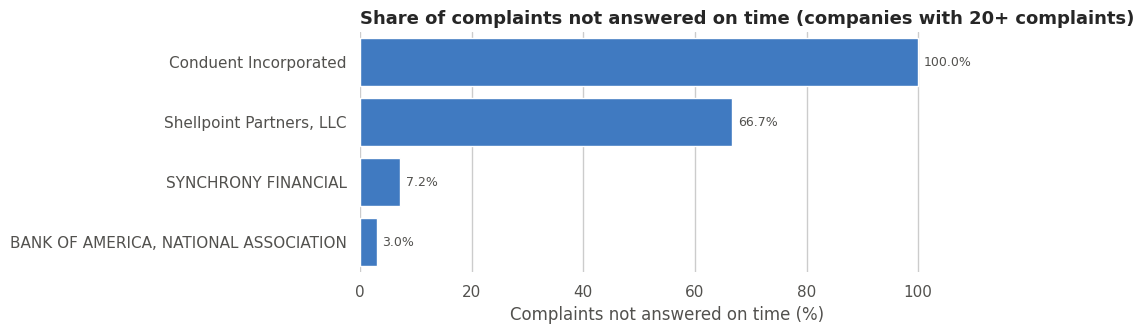

In [ ]:
fig, ax = plt.subplots(figsize=(10, 3.5))
sns.barplot(data=late, y="company_name", x="pct_not_timely", color=BAR, ax=ax)
label_bars(ax, fmt="{:.1f}%")
ax.set_title("Share of complaints not answered on time (companies with 20+ complaints)", loc="left")
ax.set(xlabel="Complaints not answered on time (%)", ylabel="")
ax.set_xlim(0, 110)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

**Finding:** only a few companies with 20+ complaints have any late responses. One of them answered none of its complaints on time, which makes it the clearest outlier in the sample. Companies with no late responses don't appear in this chart.

## Q5. Where did the late responses come from?
*Why it matters:* if late responses are spread thinly, the problem is industry-wide; if a few companies produce most of them, follow-up can be targeted. All companies are included here, with no minimum complaint count.

In [ ]:
q_late_share = """
select fc.company_name, count(*) as late_count,
       round(ratio_to_report(count(*)) over () * 100, 1) as pct_of_late
from consumer_complaints cc
join financial_companies fc on fc.company_id = cc.company_id
where cc.timely_response = 'No'
group by fc.company_name
order by late_count desc
fetch first 8 rows only
"""
late_share = pd.read_sql(q_late_share, engine)
late_share["late_count"] = late_share["late_count"].astype(int)
late_share["pct_of_late"] = late_share["pct_of_late"].astype(float)
late_share

,company_name,late_count,pct_of_late
0,Conduent Incorporated,56,40.3
1,MOHELA,16,11.5
2,"Shellpoint Partners, LLC",14,10.1
3,"Palmetto Clean Technology, Inc.",6,4.3
4,Servicer under contract with Federal Student Aid,6,4.3
5,SYNCHRONY FINANCIAL,6,4.3
6,Essential Lending Inc,4,2.9
7,NISSAN MOTOR ACCEPTANCE COMPANY LLC,3,2.2


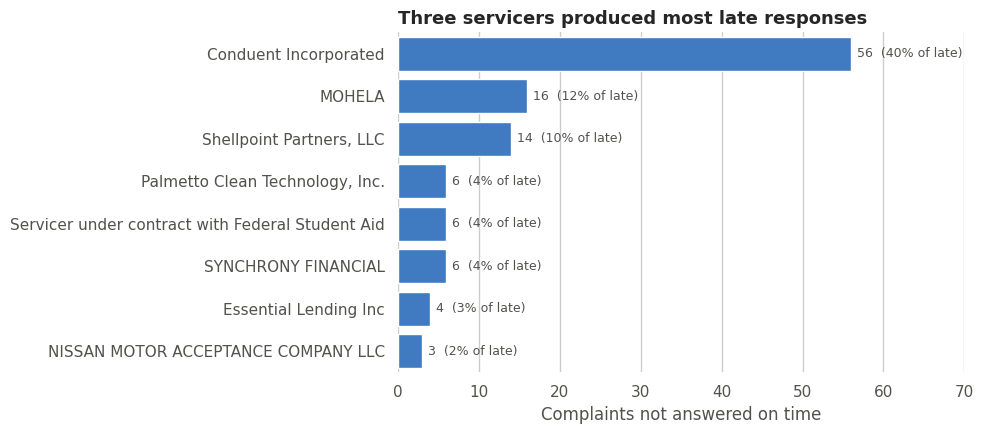

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=late_share, y="company_name", x="late_count", color=BAR, ax=ax)
for bar, pct in zip(ax.patches, late_share["pct_of_late"]):
    ax.annotate(f"{bar.get_width():,.0f}  ({pct:.0f}% of late)",
                (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=INK)
ax.set_title("Three servicers produced most late responses", loc="left")
ax.set(xlabel="Complaints not answered on time", ylabel="")
ax.margins(x=0.25)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

**Finding:** Conduent (56), MOHELA (16) and Shellpoint (14) produced 86 of the 139 late responses (62%). None of the three credit bureaus appears: they answered every complaint on time.

## Q6. Which companies most often close complaints with relief?
*Why it matters:* relief (monetary or non-monetary) means the company changed something for the consumer rather than only explaining. Companies with at least 20 complaints. (Same result as SQL Q7.)

In [ ]:
q7 = """
select company_name, company_total,
       round(sum(response_share) * 100, 1) as pct_with_relief
from (
    select fc.company_name, cc.company_response,
           sum(count(*)) over (partition by fc.company_name) as company_total,
           ratio_to_report(count(*)) over (partition by fc.company_name) as response_share
    from consumer_complaints cc
    join financial_companies fc on fc.company_id = cc.company_id
    group by fc.company_name, cc.company_response
) q
where company_total >= 20
  and company_response like '%relief%'
group by company_name, company_total
order by pct_with_relief desc
"""
relief = pd.read_sql(q7, engine)
relief["pct_with_relief"] = relief["pct_with_relief"].astype(float)
relief["company_total"] = relief["company_total"].astype(int)
relief

,company_name,company_total,pct_with_relief
0,"Kriya Capital, LLC",42,90.5
1,"Portfolio Recovery Associates, LLC",23,56.5
2,Experian Information Solutions Inc.,5892,52.6
3,"Paypal Holdings, Inc",21,52.4
4,"EQUIFAX, INC.",553,41.8
5,"CITIBANK, N.A.",21,38.1
6,"BANK OF AMERICA, NATIONAL ASSOCIATION",66,36.4
7,NAVY FEDERAL CREDIT UNION,21,33.3
8,CAPITAL ONE FINANCIAL CORPORATION,31,22.6
9,WELLS FARGO & COMPANY,29,20.7


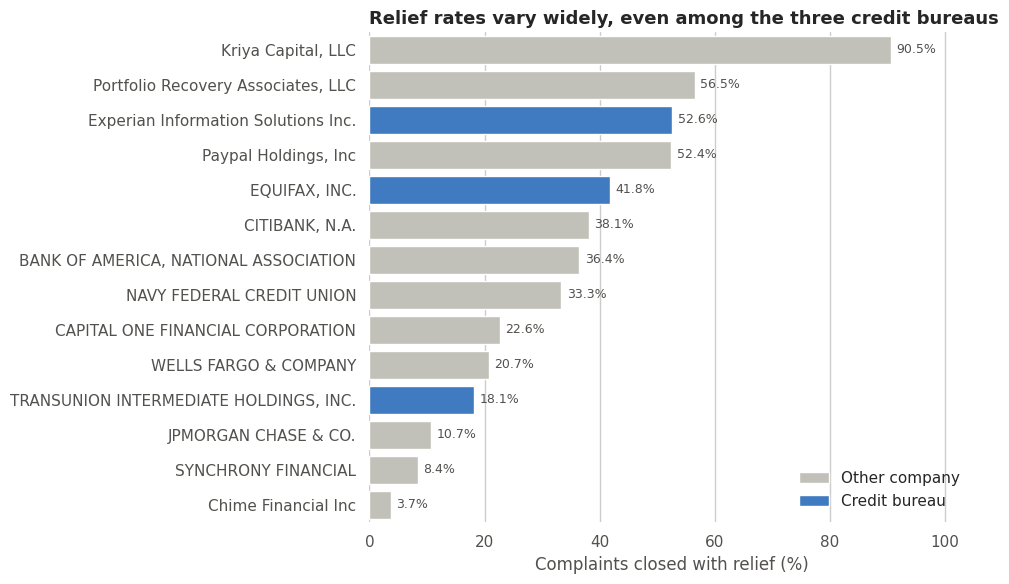

In [ ]:
BUREAUS = ["Experian Information Solutions Inc.", "EQUIFAX, INC.", "TRANSUNION INTERMEDIATE HOLDINGS, INC."]
relief["group"] = relief["company_name"].isin(BUREAUS).map({True: "Credit bureau", False: "Other company"})
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=relief, y="company_name", x="pct_with_relief", hue="group", dodge=False,
            palette={"Credit bureau": BAR, "Other company": "#c3c2b7"}, ax=ax)
ax.legend(title="", frameon=False, loc="lower right")
label_bars(ax, fmt="{:.1f}%")
ax.set_title("Relief rates vary widely, even among the three credit bureaus", loc="left")
ax.set(xlabel="Complaints closed with relief (%)", ylabel="")
ax.set_xlim(0, 105)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

**Finding:** Experian closed 52.6% of its complaints with relief, Equifax 41.8% and TransUnion 18.1%, even though all three mostly handle the same issue (incorrect information on a credit report). Companies with no relief at all, such as Conduent and Shellpoint, are not shown because the query only keeps companies with at least one relief outcome.

## 8. Conclusions
**Recommendation:** rank companies on how they respond to complaints, not on how many they receive.
- **Volume points at the wrong companies:** the three credit bureaus received 90% of complaints and answered every one on time (sections 2 and 5 / Q1 and Q4).
- **Late responses are concentrated:** three servicers produced 62% of the 139 late responses (section 6 / Q5).
- **The same problem gets different outcomes:** bureau relief rates range from 18.1% to 52.6% (section 7 / Q6).
